# Proyecto 2 — Heap con imágenes

Página de referencia: <https://www.cs.usfca.edu/~galles/visualization/Heap.html>

En el capítulo 9 construyeron una clase `Heap` (min heap) cuyo arreglo queda **igual** al de la página después de cada operación. En este proyecto, a ese heap se le agrega la posibilidad de **tomar una imagen** de cómo queda constituido después de cada operación.

## 1. El heap

Use **su propia** clase `Heap` del cuaderno `ch09_construyendo_un_heap.ipynb`, con las mismas convenciones de la página:

- `self.arreglo[0]` es `-INF` (`float('-inf')`) y no hace parte del heap.
- La raíz está en `self.arreglo[1]`.
- Los hijos de la posición `i` están en `2*i` y `2*i + 1`.

Solo debe tener las tres operaciones de la página:

| Botón de la página | Método |
|---|---|
| **Insert** | `insert(valor)` |
| **Remove Smallest** | `remove_smallest()` |
| **BuildHeap** | `build_heap(lista)` |

Después de cada operación, `self.arreglo` debe quedar **igual** al arreglo de la página.

## 2. `build_heap(lista)`

Recibe una lista y deja `self.arreglo` convertido en un heap **igual** al que produce el botón **BuildHeap** de la página.

El botón BuildHeap de la página usa la lista `[31, 30, 29, ..., 1]`; con esa lista puede comparar su resultado.

## 3. La imagen

Cada una de las tres operaciones recibe un parámetro opcional `imagen`:

```python
H.insert(5, imagen=True)
H.remove_smallest(imagen=True)
H.build_heap([31, 30, 29, 28], imagen=True)
```

- Si `imagen=False` (valor por defecto), la operación no muestra nada.
- Si `imagen=True`, al terminar la operación se muestra una imagen del **árbol** del heap.

La imagen muestra **solo el estado final** del heap después de la operación (no los pasos intermedios ni una animación):

- cada nodo con su valor;
- las aristas entre cada nodo y sus hijos;
- la raíz arriba y cada nivel debajo del anterior, con los hijos izquierdos a la izquierda y los derechos a la derecha, como el árbol de la página.

El `-INF` de la posición 0 no aparece en la imagen.

## 4. Ejemplo

```python
from heap import Heap

H = Heap()
H.insert(10)
H.insert(4)
H.insert(7, imagen=True)    # imagen del heap con 4, 10 y 7
H.remove_smallest(imagen=True)
```

La primera imagen debe mostrar `4` en la raíz con hijos `10` y `7`, como la página después de insertar 10, 4 y 7.

## 5. Su solución en `heap.py`

La clase `Heap` debe quedar en un archivo **`heap.py`** (con ese nombre exacto) en su repositorio, en

```
student_work/Proyecto2/heap.py
```

para luego **importarla**:

```python
from heap import Heap
```

Escriba su clase en la celda de abajo. La primera línea, `%%writefile heap.py`, **no** ejecuta el código: guarda el contenido de la celda en el archivo `heap.py`, en la misma carpeta de este cuaderno. Cada vez que modifique su clase, vuelva a ejecutar esa celda para sobrescribir el archivo.

- El archivo debe poder importarse sin errores: no deje pruebas sueltas en él. Si quiere dejar pruebas dentro del `.py`, póngalas debajo de `if __name__ == "__main__":`.
- `from heap import Heap` no toma sus cambios hasta que reinicie el kernel; para releer el archivo sin reiniciar use `importlib.reload` como en la celda de prueba.
- No olvide hacer *commit* y *push* de `heap.py` a su repositorio.

In [1]:
%%writefile heap.py
import math
import matplotlib.pyplot as plt


class Heap:

    def __init__(self):
        self.arreglo = [float('-inf')]
        self.ultima_imagen = None    # última figura mostrada (para guardarla en PNG)

    # ------------------------------------------------------------------
    # Operaciones de la página
    # ------------------------------------------------------------------

    def insert(self, valor, imagen=False):
        """Botón Insert: agrega `valor` al final y lo sube (sift up)."""
        self._validar_valor(valor)
        self.arreglo.append(valor)
        self._subir(len(self.arreglo) - 1)
        if imagen:
            self._mostrar_imagen()

    def remove_smallest(self, imagen=False):
        """Botón Remove Smallest: quita y devuelve la raíz (el mínimo).

        Si el heap está vacío no modifica nada y devuelve None,
        igual que la página, que solo avisa que no hay qué quitar.
        """
        if len(self.arreglo) == 1:          # solo queda el -INF
            menor = None
        else:
            menor = self.arreglo[1]
            ultimo = self.arreglo.pop()     # se saca la última hoja
            if len(self.arreglo) > 1:       # si quedan elementos,
                self.arreglo[1] = ultimo    # la última hoja pasa a la raíz
                self._bajar(1)              # y se baja (heapify)
        if imagen:
            self._mostrar_imagen()
        return menor

    def build_heap(self, lista, imagen=False):
        """Botón BuildHeap: reemplaza el contenido por `lista` y lo
        convierte en heap bajando cada nodo interno, desde el último
        padre (n // 2) hasta la raíz (construcción de abajo hacia arriba).
        """
        if not isinstance(lista, list):
            raise TypeError("build_heap espera una lista, recibió "
                            + type(lista).__name__)
        for valor in lista:                 # se valida todo antes de
            self._validar_valor(valor)      # tocar el heap actual
        # El + crea una lista NUEVA: la lista del usuario no se modifica
        self.arreglo = [float('-inf')] + lista
        n = len(self.arreglo) - 1
        for i in range(n // 2, 0, -1):
            self._bajar(i)
        if imagen:
            self._mostrar_imagen()

    # ------------------------------------------------------------------
    # Auxiliares del heap
    # ------------------------------------------------------------------

    def _validar_valor(self, valor):
        """Solo se aceptan números comparables entre sí (int o float)."""
        if isinstance(valor, bool) or not isinstance(valor, (int, float)):
            raise TypeError("El heap solo acepta números, recibió "
                            + repr(valor))
        if valor != valor:                  # NaN es el único valor distinto de sí mismo
            raise ValueError("El heap no acepta NaN: no se puede comparar")

    def _intercambiar(self, i, j):
        self.arreglo[i], self.arreglo[j] = self.arreglo[j], self.arreglo[i]

    def _subir(self, i):
        """Sube el elemento de la posición i mientras sea MENOR que su padre.
        Con valores iguales no se intercambia (igual que la página)."""
        while i > 1 and self.arreglo[i] < self.arreglo[i // 2]:
            self._intercambiar(i, i // 2)
            i = i // 2

    def _bajar(self, i):
        """Baja el elemento de la posición i (heapify) mientras sea MAYOR
        que su hijo menor. Si los dos hijos son iguales se elige el
        izquierdo (igual que la página)."""
        n = len(self.arreglo) - 1
        while 2 * i <= n:                   # mientras i tenga al menos un hijo
            menor = 2 * i                   # hijo izquierdo
            if 2 * i + 1 <= n and self.arreglo[2 * i + 1] < self.arreglo[2 * i]:
                menor = 2 * i + 1           # el derecho es estrictamente menor
            if self.arreglo[i] > self.arreglo[menor]:
                self._intercambiar(i, menor)
                i = menor
            else:
                break

    # ------------------------------------------------------------------
    # Imagen del árbol
    # ------------------------------------------------------------------

    def _posicion(self, i):
        """Coordenadas (x, y) del nodo en la posición i del arreglo.

        El nivel es floor(log2(i)): la raíz (i=1) está en el nivel 0,
        las posiciones 2 y 3 en el nivel 1, de 4 a 7 en el nivel 2...
        Cada nivel divide el ancho [0, 1] en 2**nivel casillas iguales y
        el nodo se dibuja en el centro de la suya, así los hijos
        izquierdos quedan a la izquierda y los derechos a la derecha.
        """
        nivel = int(math.log2(i))
        primero_del_nivel = 2 ** nivel
        casilla = i - primero_del_nivel
        x = (casilla + 0.5) / primero_del_nivel
        y = -nivel
        return x, y

    def _dibujar(self):
        """Construye y devuelve la figura del árbol (estado actual)."""
        n = len(self.arreglo) - 1
        niveles = int(math.log2(n)) + 1 if n > 0 else 1
        ancho = min(max(4, 0.9 * 2 ** (niveles - 1)), 20)
        fig, ax = plt.subplots(figsize=(ancho, 1.3 * niveles + 0.5))
        ax.axis('off')

        if n == 0:
            ax.text(0.5, 0.5, "Heap vacío", ha='center', va='center',
                    fontsize=14, transform=ax.transAxes)
            return fig

        # Aristas: de cada nodo i (desde 2) hacia su padre i // 2
        for i in range(2, n + 1):
            x1, y1 = self._posicion(i // 2)
            x2, y2 = self._posicion(i)
            ax.plot([x1, x2], [y1, y2], color='black', linewidth=1, zorder=1)

        # Nodos: un círculo con su valor (se omite la posición 0, el -INF)
        for i in range(1, n + 1):
            x, y = self._posicion(i)
            ax.scatter(x, y, s=900, color='white', edgecolors='black', zorder=2)
            ax.text(x, y, str(self.arreglo[i]), ha='center', va='center',
                    fontsize=10, zorder=3)

        ax.set_xlim(-0.02, 1.02)
        ax.set_ylim(-niveles + 0.5, 0.5)
        return fig

    def _mostrar_imagen(self):
        fig = self._dibujar()
        self.ultima_imagen = fig    # se guarda para poder hacer savefig después
        plt.show()
        plt.close(fig)      # la quita de pyplot; el objeto sigue sirviendo para savefig

    def __repr__(self):
        return "Heap(" + str(self.arreglo) + ")"

Overwriting heap.py


In [3]:
import importlib
import heap
importlib.reload(heap)          # vuelve a leer heap.py si lo cambió
from heap import Heap

H = Heap()
H.insert(10)
H.insert(4)
H.insert(7, imagen=True)

ModuleNotFoundError: spec not found for the module 'heap'

## 6. Prueba: 5 inserciones con fotos

Todos hacen **la misma prueba**: empezando con un heap vacío, inserte **en este orden** los valores

```python
[15, 8, 20, 3, 10]
```

con `imagen=True` en cada inserción, y guarde las **5 imágenes** (una después de cada inserción) como archivos PNG en la carpeta `fotos`, dentro de `student_work/Proyecto2`:

```
student_work/Proyecto2/
├── heap.py
└── fotos/
    ├── insert_1.png    # después de insertar 15
    ├── insert_2.png    # después de insertar 8
    ├── insert_3.png    # después de insertar 20
    ├── insert_4.png    # después de insertar 3
    └── insert_5.png    # después de insertar 10
```

- Use exactamente esos nombres de archivo y esa carpeta.
- Cada foto muestra el árbol del heap **completo** después de esa inserción.
- No olvide hacer *commit* y *push* de la carpeta `fotos`.

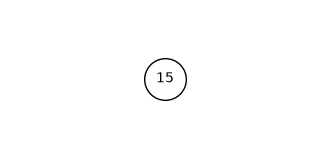

1 [-inf, 15]


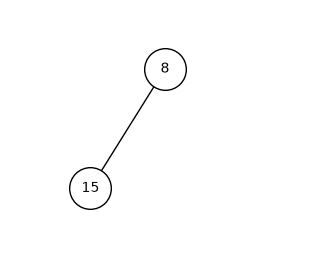

2 [-inf, 8, 15]


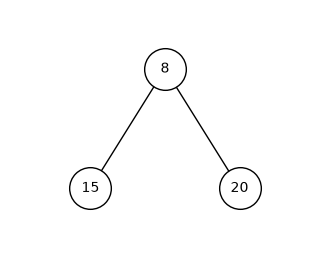

3 [-inf, 8, 15, 20]


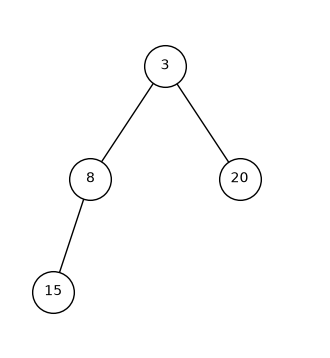

4 [-inf, 3, 8, 20, 15]


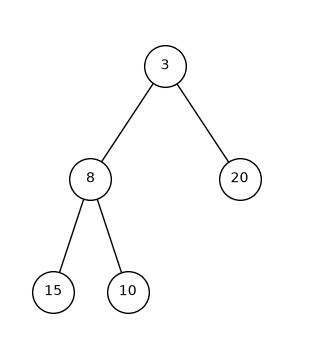

5 [-inf, 3, 8, 20, 15, 10]


In [2]:
import os
import importlib
import heap
importlib.reload(heap)
from heap import Heap

os.makedirs("fotos", exist_ok=True)     # crea la carpeta fotos si no existe

valores = [15, 8, 20, 3, 10]            # NO cambie esta lista

H = Heap()
for i, v in enumerate(valores, start=1):
    H.insert(v, imagen=True)
    # guarde aquí la imagen de esta inserción en f"fotos/insert_{i}.png"
    print(i, H.arreglo)